<a href="https://colab.research.google.com/github/Axaxxa/6005-portfolio-/blob/main/6005(week2_portfolio1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
import glob
import shap
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

import kagglehub
# Download latest version
path = kagglehub.dataset_download("abhishek14398/salary-dataset-simple-linear-regression")
print("Path to dataset files:", path)
# Find the CSV file inside the downloaded dataset directory
csv_files = glob.glob(os.path.join(path, "*.csv"))

# Load the dataset correctly
df = pd.read_csv(csv_files[0])
print(df.head())

Using Colab cache for faster access to the 'salary-dataset-simple-linear-regression' dataset.
Path to dataset files: /kaggle/input/salary-dataset-simple-linear-regression
   Unnamed: 0  YearsExperience   Salary
0           0              1.2  39344.0
1           1              1.4  46206.0
2           2              1.6  37732.0
3           3              2.1  43526.0
4           4              2.3  39892.0


Mean Squared Error: 49830096.86
R² Score: 0.90


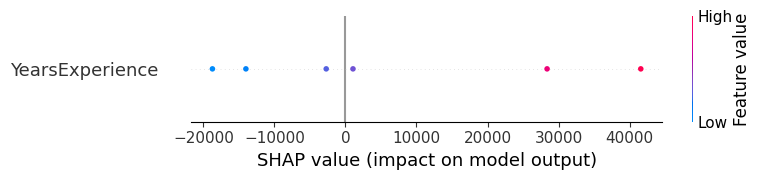

In [2]:

# Create a DataFrame from the data and target
X = df[["YearsExperience"]]
y = df["Salary"]

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train a linear regression model
model = LinearRegression()
model.fit(X_train, y_train)

# Predict and evaluate
y_pred = model.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print(f"Mean Squared Error: {mse:.2f}")
print(f"R² Score: {r2:.2f}")

# SHAP explanation
explainer = shap.Explainer(model.predict, X_train)
shap_values = explainer(X_test)

# SHAP summary plot
shap.summary_plot(shap_values, X_test)

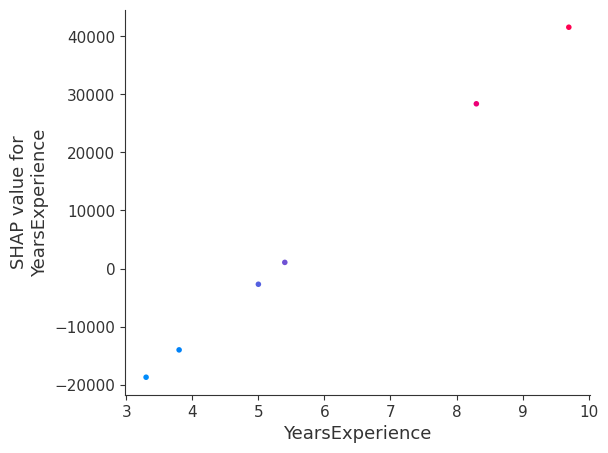

In [3]:
# Generate SHAP dependence plots for input features
selected_features = ['YearsExperience']
for feature in selected_features:
    shap.dependence_plot(feature, shap_values.values, X_test, feature_names=X_test.columns)
    plt.savefig(f"shap_dependence_{feature}.png")
    plt.close()

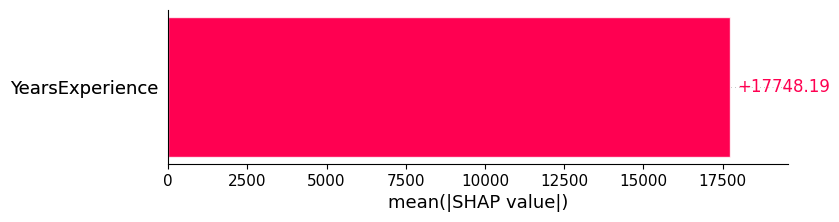

In [4]:
# Use SHAP's built-in bar plot to show feature importance
shap.plots.bar(shap_values)
plt.savefig("shap_feature_importances.png")
plt.close()